# 1. Data Loading and Feature Engineering

In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

In [2]:
df = pd.read_csv('dataset_with_regime.csv', parse_dates=['observation_date'])
print(f"Dataset: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset: 1559 rows, 23 columns


,observation_date,Brent_Price,DTWEXBGS,EFFR,Gas_Price,Gold_Price,OVX_Close,WTI_Price,oil_return,WCESTUS1,...,GPRT,GPRC,GEPUCURRENT,CPILFESL,INDPRO,industrial_production_growth,rolling_entropy,hidden_state,regime_label,WTI_Price_next
0,2020-03-26,26.34,122.4308,0.10,1.73,1650.1,150.06,22.60,-0.0803,455360,...,97.09,9.93,318.4649,267.054,97.4078,-0.0391,2.610812,-6.091771,0,21.51
1,2020-03-27,24.93,122.4007,0.10,1.70,1623.9,175.88,21.51,-0.0494,469193,...,97.09,9.93,318.4649,267.054,97.4078,-0.0391,2.610812,-6.236685,0,20.09
2,2020-03-30,22.76,123.2883,0.09,1.65,1622.0,174.22,20.09,-0.0683,469193,...,97.09,9.93,318.4649,267.054,97.4078,-0.0391,2.663805,-6.017366,0,20.48
3,2020-03-31,22.74,122.5301,0.08,1.71,1583.4,170.55,20.48,0.0192,469193,...,97.09,9.93,318.4649,267.054,97.4078,-0.0391,2.696616,-5.855940,0,20.31
4,2020-04-01,24.74,123.7933,0.06,1.69,1578.2,158.98,20.31,-0.0083,469193,...,81.76,-15.33,328.1326,265.746,84.5619,-0.1319,2.663805,-5.944645,0,25.32


In [3]:
df['lag1'] = df['oil_return'].shift(1)
df['lag2'] = df['oil_return'].shift(2)
df['lag_price'] = df['WTI_Price'].shift(1)

# Target: log return (predict next-day return, then convert to price)
df['target_return'] = np.log(df['WTI_Price_next'] / df['WTI_Price'])

# Drop rows with NaN from lag creation
df = df.dropna().copy()

print(f"After lag features: {df.shape[0]} rows")

After lag features: 1555 rows


In [4]:
split_idx = int(len(df) * 0.8)

train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy()

print(f"Train: {len(train_df)} rows ({train_df['observation_date'].min().date()} to {train_df['observation_date'].max().date()})")
print(f"Test:  {len(test_df)} rows ({test_df['observation_date'].min().date()} to {test_df['observation_date'].max().date()})")

Train: 1244 rows (2020-03-30 to 2025-01-06)
Test:  311 rows (2025-01-07 to 2026-03-12)


# 2. Baseline XGBoost Model

In [5]:
baseline_features = [
    'Brent_Price', 'DTWEXBGS', 'EFFR', 'Gas_Price', 'Gold_Price', 'OVX_Close',
    'WCESTUS1', 'supply_shock', 'supply_shock_pct',
    'GPR', 'GPRT', 'GPRC', 'GEPUCURRENT', 'CPILFESL',
    'INDPRO', 'industrial_production_growth',
    'lag1', 'lag2', 'lag_price'
]

enhanced_features = baseline_features + ['rolling_entropy', 'hidden_state', 'regime_label']

target_col = 'target_return'

In [6]:
xgb_params = dict(
    n_estimators=5000,
    learning_rate=0.02,
    max_depth=3,
    subsample=0.7,
    colsample_bytree=0.7,
    reg_alpha=0.5,
    reg_lambda=2,
    random_state=42,
    objective='reg:squarederror'
)

model_baseline = xgb.XGBRegressor(**xgb_params)
model_baseline.fit(train_df[baseline_features], train_df[target_col])

y_pred_baseline_train = model_baseline.predict(train_df[baseline_features])
y_pred_baseline_test = model_baseline.predict(test_df[baseline_features])

price_pred_baseline = test_df['WTI_Price'].values * np.exp(y_pred_baseline_test)
price_true = test_df['WTI_Price_next'].values

rmse_baseline = np.sqrt(mean_squared_error(price_true, price_pred_baseline))
mae_baseline = mean_absolute_error(price_true, price_pred_baseline)
mape_baseline = np.mean(np.abs((price_true - price_pred_baseline) / price_true)) * 100

print("=== Baseline XGBoost ===")
print(f"RMSE: {rmse_baseline:.4f}")
print(f"MAE:  {mae_baseline:.4f}")
print(f"MAPE: {mape_baseline:.4f}%")

=== Baseline XGBoost ===
RMSE: 1.8994
MAE:  1.2794
MAPE: 1.9258%


# 3. Enhanced XGBoost Model (with Regime Features)

In [7]:
model_enhanced = xgb.XGBRegressor(**xgb_params)
model_enhanced.fit(train_df[enhanced_features], train_df[target_col])

y_pred_enhanced_test = model_enhanced.predict(test_df[enhanced_features])

price_pred_enhanced = test_df['WTI_Price'].values * np.exp(y_pred_enhanced_test)

rmse_enhanced = np.sqrt(mean_squared_error(price_true, price_pred_enhanced))
mae_enhanced = mean_absolute_error(price_true, price_pred_enhanced)
mape_enhanced = np.mean(np.abs((price_true - price_pred_enhanced) / price_true)) * 100

print("=== Enhanced XGBoost (with Regime Features) ===")
print(f"RMSE: {rmse_enhanced:.4f}")
print(f"MAE:  {mae_enhanced:.4f}")
print(f"MAPE: {mape_enhanced:.4f}%")

=== Enhanced XGBoost (with Regime Features) ===
RMSE: 1.9019
MAE:  1.2365
MAPE: 1.8501%


# 4. Model Comparison

In [8]:
comparison = pd.DataFrame({
    'Model': ['Baseline XGBoost', 'Enhanced XGBoost (+ Regime)'],
    'RMSE': [rmse_baseline, rmse_enhanced],
    'MAE': [mae_baseline, mae_enhanced],
    'MAPE (%)': [mape_baseline, mape_enhanced]
}).round(4)

comparison.loc[2] = [
    'Improvement (%)',
    f"{(rmse_baseline - rmse_enhanced) / rmse_baseline * 100:.2f}%",
    f"{(mae_baseline - mae_enhanced) / mae_baseline * 100:.2f}%",
    f"{(mape_baseline - mape_enhanced) / mape_baseline * 100:.2f}%"
]

comparison

,Model,RMSE,MAE,MAPE (%)
0,Baseline XGBoost,1.8994,1.2794,1.9258
1,Enhanced XGBoost (+ Regime),1.9019,1.2365,1.8501
2,Improvement (%),-0.13%,3.36%,3.93%


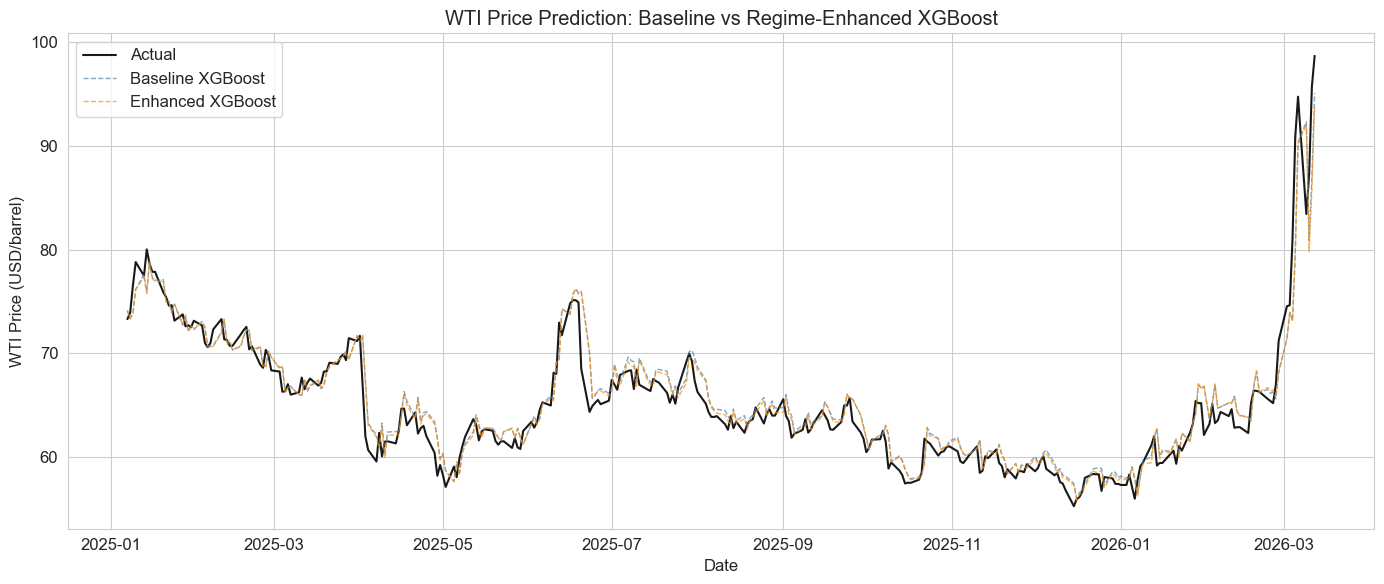

In [9]:
test_dates = test_df['observation_date'].values

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(test_dates, price_true, color='black', linewidth=1.5, label='Actual', alpha=0.9)
ax.plot(test_dates, price_pred_baseline, color='steelblue', linewidth=1,
        label='Baseline XGBoost', alpha=0.7, linestyle='--')
ax.plot(test_dates, price_pred_enhanced, color='darkorange', linewidth=1,
        label='Enhanced XGBoost', alpha=0.7, linestyle='--')
ax.set_xlabel('Date')
ax.set_ylabel('WTI Price (USD/barrel)')
ax.set_title('WTI Price Prediction: Baseline vs Regime-Enhanced XGBoost')
ax.legend()
plt.tight_layout()
plt.show()

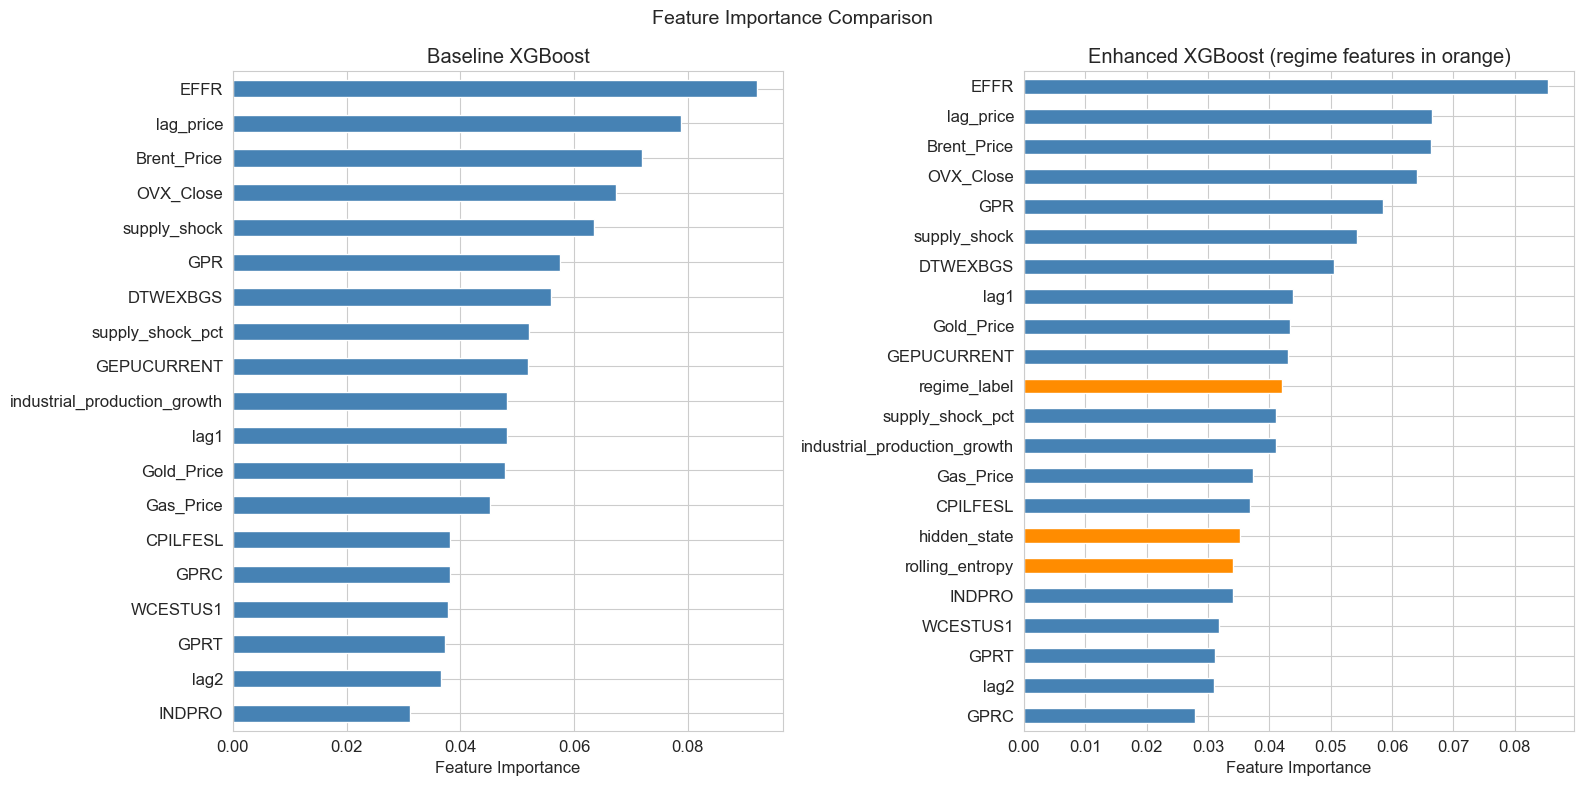

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

imp_baseline = pd.Series(model_baseline.feature_importances_,
                          index=baseline_features).sort_values()
imp_baseline.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Baseline XGBoost')
axes[0].set_xlabel('Feature Importance')

imp_enhanced = pd.Series(model_enhanced.feature_importances_,
                          index=enhanced_features).sort_values()
colors = ['darkorange' if f in ['rolling_entropy', 'hidden_state', 'regime_label']
          else 'steelblue' for f in imp_enhanced.index]
imp_enhanced.plot(kind='barh', ax=axes[1], color=colors)
axes[1].set_title('Enhanced XGBoost (regime features in orange)')
axes[1].set_xlabel('Feature Importance')

fig.suptitle('Feature Importance Comparison', fontsize=14)
plt.tight_layout()
plt.show()

## Summary

**Part II Findings:**
- The Enhanced XGBoost model incorporates three regime-derived features: `rolling_entropy`, `hidden_state`, and `regime_label`.
- Comparison metrics (RMSE, MAE, MAPE) are reported in the table above.
- The feature importance plot shows how regime features rank relative to traditional market variables.

# 5. Prophet Model — Baseline vs Enhanced

In [ ]:
from prophet import Prophet
from sklearn.preprocessing import MinMaxScaler

In [ ]:
# Prophet requires 'ds' and 'y' columns
# Use the same dataset as XGBoost (df is already loaded and has lag features)
prophet_df = df.copy()
prophet_df = prophet_df.rename(columns={'observation_date': 'ds', 'WTI_Price': 'y'})

# Baseline regressors (from group project, excluding dropped ones)
prophet_baseline_regressors = [
    'Brent_Price', 'DTWEXBGS', 'EFFR', 'Gas_Price', 'Gold_Price', 'OVX_Close',
    'WCESTUS1', 'supply_shock_pct', 'GEPUCURRENT', 'CPILFESL', 'INDPRO',
    'lag1', 'lag2', 'lag_price'
]

# Enhanced regressors: baseline + regime features
prophet_enhanced_regressors = prophet_baseline_regressors + ['rolling_entropy', 'hidden_state', 'regime_label']

# Same 80/20 chronological split
split_idx_p = int(len(prophet_df) * 0.8)
prophet_train = prophet_df.iloc[:split_idx_p].copy()
prophet_test  = prophet_df.iloc[split_idx_p:].copy()

print(f"Prophet Train: {len(prophet_train)} rows")
print(f"Prophet Test:  {len(prophet_test)} rows")

In [ ]:
def build_and_fit_prophet(train_df, regressors):
    model = Prophet(
        seasonality_mode='multiplicative',
        changepoint_prior_scale=0.05,
        seasonality_prior_scale=10.0,
        n_changepoints=25,
        daily_seasonality=False,
        weekly_seasonality=True,
        yearly_seasonality=True
    )
    for col in regressors:
        model.add_regressor(col)
    model.fit(train_df[['ds', 'y'] + regressors])
    return model

# Baseline Prophet
prophet_baseline = build_and_fit_prophet(prophet_train, prophet_baseline_regressors)
forecast_baseline = prophet_baseline.predict(prophet_test[['ds'] + prophet_baseline_regressors])

price_pred_prophet_baseline = forecast_baseline['yhat'].values
price_true_prophet = prophet_test['WTI_Price_next'].values  # next-day actual

rmse_prophet_baseline = np.sqrt(mean_squared_error(price_true_prophet, price_pred_prophet_baseline))
mae_prophet_baseline  = mean_absolute_error(price_true_prophet, price_pred_prophet_baseline)
mape_prophet_baseline = np.mean(np.abs((price_true_prophet - price_pred_prophet_baseline) / price_true_prophet)) * 100

print("=== Baseline Prophet ===")
print(f"RMSE: {rmse_prophet_baseline:.4f}")
print(f"MAE:  {mae_prophet_baseline:.4f}")
print(f"MAPE: {mape_prophet_baseline:.4f}%")

In [ ]:
# Enhanced Prophet (with regime features)
prophet_enhanced = build_and_fit_prophet(prophet_train, prophet_enhanced_regressors)
forecast_enhanced = prophet_enhanced.predict(prophet_test[['ds'] + prophet_enhanced_regressors])

price_pred_prophet_enhanced = forecast_enhanced['yhat'].values

rmse_prophet_enhanced = np.sqrt(mean_squared_error(price_true_prophet, price_pred_prophet_enhanced))
mae_prophet_enhanced  = mean_absolute_error(price_true_prophet, price_pred_prophet_enhanced)
mape_prophet_enhanced = np.mean(np.abs((price_true_prophet - price_pred_prophet_enhanced) / price_true_prophet)) * 100

print("=== Enhanced Prophet (+ Regime) ===")
print(f"RMSE: {rmse_prophet_enhanced:.4f}")
print(f"MAE:  {mae_prophet_enhanced:.4f}")
print(f"MAPE: {mape_prophet_enhanced:.4f}%")

In [ ]:
# Comparison table
prophet_comparison = pd.DataFrame({
    'Model': ['Baseline Prophet', 'Enhanced Prophet (+ Regime)'],
    'RMSE': [rmse_prophet_baseline, rmse_prophet_enhanced],
    'MAE':  [mae_prophet_baseline,  mae_prophet_enhanced],
    'MAPE (%)': [mape_prophet_baseline, mape_prophet_enhanced]
}).round(4)
prophet_comparison.loc[2] = [
    'Improvement (%)',
    f"{(rmse_prophet_baseline - rmse_prophet_enhanced) / rmse_prophet_baseline * 100:.2f}%",
    f"{(mae_prophet_baseline  - mae_prophet_enhanced)  / mae_prophet_baseline  * 100:.2f}%",
    f"{(mape_prophet_baseline - mape_prophet_enhanced) / mape_prophet_baseline * 100:.2f}%"
]
display(prophet_comparison)

# Prediction plot
fig, ax = plt.subplots(figsize=(14, 5))
test_dates_p = prophet_test['ds'].values
ax.plot(test_dates_p, price_true_prophet,          color='black',     linewidth=1.5, label='Actual')
ax.plot(test_dates_p, price_pred_prophet_baseline, color='steelblue', linewidth=1, linestyle='--', label='Baseline Prophet', alpha=0.7)
ax.plot(test_dates_p, price_pred_prophet_enhanced, color='darkorange',linewidth=1, linestyle='--', label='Enhanced Prophet', alpha=0.7)
ax.set_xlabel('Date'); ax.set_ylabel('WTI Price (USD/barrel)')
ax.set_title('WTI Price Prediction: Baseline vs Regime-Enhanced Prophet')
ax.legend(); plt.tight_layout(); plt.show()

# 6. LSTM Model — Baseline vs Enhanced

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import RobustScaler
from copy import deepcopy

In [ ]:
# LSTM targets log return (like group project), then converts to price
lstm_df = df.copy()

# Additional features from group project
lstm_df['log_price']     = np.log(lstm_df['WTI_Price'])
lstm_df['log_rtn']       = np.log(lstm_df['WTI_Price'] / lstm_df['WTI_Price'].shift(1))
lstm_df['abs_log_rtn']   = lstm_df['log_rtn'].abs()
lstm_df['rolling_std_7'] = lstm_df['WTI_Price'].shift(1).rolling(7).std()
lstm_df['rolling_std_14']= lstm_df['WTI_Price'].shift(1).rolling(14).std()
lstm_df['rolling_return_7'] = lstm_df['log_rtn'].rolling(7).mean()
lstm_df['MACD'] = lstm_df['log_price'].ewm(span=12, adjust=False).mean() - lstm_df['log_price'].ewm(span=26, adjust=False).mean()
lstm_df = lstm_df.dropna().copy().reset_index(drop=True)

# LSTM hyperparameters (fixed, based on group project best params)
SEQ_LENGTH  = 21
HIDDEN_SIZE = 64
NUM_LAYERS  = 2
DROPOUT     = 0.2
BATCH_SIZE  = 32
NUM_EPOCHS  = 100
PATIENCE    = 15
LR          = 1e-3

# Baseline feature columns
lstm_baseline_features = [
    'Brent_Price', 'DTWEXBGS', 'EFFR', 'Gas_Price', 'Gold_Price', 'OVX_Close',
    'WCESTUS1', 'supply_shock_pct', 'GEPUCURRENT', 'CPILFESL', 'INDPRO',
    'log_rtn', 'abs_log_rtn', 'rolling_std_7', 'rolling_std_14',
    'rolling_return_7', 'MACD'
]

# Enhanced feature columns
lstm_enhanced_features = lstm_baseline_features + ['rolling_entropy', 'hidden_state', 'regime_label']

# 80/20 chronological split
split_idx_l = int(len(lstm_df) * 0.8)
val_split   = int(split_idx_l * 0.9)   # last 10% of train as validation

print(f"LSTM Train: {split_idx_l} rows, Val: {split_idx_l - val_split} rows, Test: {len(lstm_df) - split_idx_l} rows")

In [ ]:
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, dropout):
        super(LSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h0 = torch.zeros(NUM_LAYERS, x.size(0), HIDDEN_SIZE)
        c0 = torch.zeros(NUM_LAYERS, x.size(0), HIDDEN_SIZE)
        out, (h_n, _) = self.lstm(x, (h0, c0))
        return self.fc(h_n[-1])

def make_sequences(X, y, seq_length):
    xs, ys = [], []
    for i in range(len(X) - seq_length):
        xs.append(X[i:i+seq_length])
        ys.append(y[i+seq_length])
    return np.array(xs), np.array(ys)

def train_lstm(feature_cols):
    """Train LSTM with given feature columns. Returns (price_pred, price_actual)."""
    X_raw = lstm_df[feature_cols].values.astype(np.float32)
    y_raw = lstm_df[['log_rtn']].values.astype(np.float32)

    sc_x = RobustScaler()
    sc_y = RobustScaler()

    # Fit scalers on training portion only
    sc_x.fit(X_raw[:split_idx_l])
    sc_y.fit(y_raw[:split_idx_l])

    X_scaled = sc_x.transform(X_raw)
    y_scaled = sc_y.transform(y_raw)

    X_seq, y_seq = make_sequences(X_scaled, y_scaled, SEQ_LENGTH)

    # Adjust split for sequences
    train_end = split_idx_l - SEQ_LENGTH
    val_end   = val_split  - SEQ_LENGTH

    X_train = torch.tensor(X_seq[:val_end]).float()
    y_train = torch.tensor(y_seq[:val_end]).float()
    X_val   = torch.tensor(X_seq[val_end:train_end]).float()
    y_val   = torch.tensor(y_seq[val_end:train_end]).float()
    X_test  = torch.tensor(X_seq[train_end:]).float()
    y_test_tensor = torch.tensor(y_seq[train_end:]).float()

    train_dl = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=False)
    val_dl   = DataLoader(TensorDataset(X_val,   y_val),   batch_size=BATCH_SIZE, shuffle=False)

    model = LSTMModel(len(feature_cols), HIDDEN_SIZE, NUM_LAYERS, DROPOUT)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.HuberLoss()

    best_val_loss = float('inf')
    no_improve = 0
    best_state = None

    for epoch in range(NUM_EPOCHS):
        model.train()
        for xb, yb in train_dl:
            pred = model(xb)
            loss = criterion(pred, yb)
            optimizer.zero_grad(); loss.backward(); optimizer.step()

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for xb, yb in val_dl:
                val_loss += criterion(model(xb), yb).item() * xb.size(0)
        val_loss /= len(X_val)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            no_improve = 0
            best_state = deepcopy(model.state_dict())
        else:
            no_improve += 1
            if no_improve >= PATIENCE:
                break

    model.load_state_dict(best_state)
    model.eval()

    # Predict on test set
    with torch.no_grad():
        preds_scaled = model(X_test).numpy()
    preds_log_rtn = sc_y.inverse_transform(preds_scaled)

    # Convert log return to price
    wti_prev = lstm_df['WTI_Price'].values[split_idx_l + SEQ_LENGTH - 1: split_idx_l + SEQ_LENGTH - 1 + len(preds_log_rtn)]
    price_pred = wti_prev * np.exp(preds_log_rtn.flatten())

    # Actual next-day price
    price_actual = lstm_df['WTI_Price_next'].values[split_idx_l + SEQ_LENGTH - 1: split_idx_l + SEQ_LENGTH - 1 + len(preds_log_rtn)]

    return price_pred, price_actual

In [ ]:
print("Training Baseline LSTM...")
price_pred_lstm_baseline, price_true_lstm = train_lstm(lstm_baseline_features)

rmse_lstm_baseline = np.sqrt(mean_squared_error(price_true_lstm, price_pred_lstm_baseline))
mae_lstm_baseline  = mean_absolute_error(price_true_lstm, price_pred_lstm_baseline)
mape_lstm_baseline = np.mean(np.abs((price_true_lstm - price_pred_lstm_baseline) / price_true_lstm)) * 100

print("=== Baseline LSTM ===")
print(f"RMSE: {rmse_lstm_baseline:.4f}")
print(f"MAE:  {mae_lstm_baseline:.4f}")
print(f"MAPE: {mape_lstm_baseline:.4f}%")

print("\nTraining Enhanced LSTM (+ Regime)...")
price_pred_lstm_enhanced, _ = train_lstm(lstm_enhanced_features)

rmse_lstm_enhanced = np.sqrt(mean_squared_error(price_true_lstm, price_pred_lstm_enhanced))
mae_lstm_enhanced  = mean_absolute_error(price_true_lstm, price_pred_lstm_enhanced)
mape_lstm_enhanced = np.mean(np.abs((price_true_lstm - price_pred_lstm_enhanced) / price_true_lstm)) * 100

print("=== Enhanced LSTM (+ Regime) ===")
print(f"RMSE: {rmse_lstm_enhanced:.4f}")
print(f"MAE:  {mae_lstm_enhanced:.4f}")
print(f"MAPE: {mape_lstm_enhanced:.4f}%")

In [ ]:
lstm_comparison = pd.DataFrame({
    'Model': ['Baseline LSTM', 'Enhanced LSTM (+ Regime)'],
    'RMSE': [rmse_lstm_baseline, rmse_lstm_enhanced],
    'MAE':  [mae_lstm_baseline,  mae_lstm_enhanced],
    'MAPE (%)': [mape_lstm_baseline, mape_lstm_enhanced]
}).round(4)
lstm_comparison.loc[2] = [
    'Improvement (%)',
    f"{(rmse_lstm_baseline - rmse_lstm_enhanced) / rmse_lstm_baseline * 100:.2f}%",
    f"{(mae_lstm_baseline  - mae_lstm_enhanced)  / mae_lstm_baseline  * 100:.2f}%",
    f"{(mape_lstm_baseline - mape_lstm_enhanced) / mape_lstm_baseline * 100:.2f}%"
]
display(lstm_comparison)

# LSTM prediction plot
fig, ax = plt.subplots(figsize=(14, 5))
test_dates_l = lstm_df['observation_date'].values[split_idx_l + SEQ_LENGTH - 1: split_idx_l + SEQ_LENGTH - 1 + len(price_pred_lstm_baseline)]
ax.plot(test_dates_l, price_true_lstm,           color='black',     linewidth=1.5, label='Actual')
ax.plot(test_dates_l, price_pred_lstm_baseline,  color='steelblue', linewidth=1, linestyle='--', label='Baseline LSTM', alpha=0.7)
ax.plot(test_dates_l, price_pred_lstm_enhanced,  color='darkorange',linewidth=1, linestyle='--', label='Enhanced LSTM', alpha=0.7)
ax.set_xlabel('Date'); ax.set_ylabel('WTI Price (USD/barrel)')
ax.set_title('WTI Price Prediction: Baseline vs Regime-Enhanced LSTM')
ax.legend(); plt.tight_layout(); plt.show()

# 7. Full Model Comparison Summary

In [ ]:
summary = pd.DataFrame([
    {'Model': 'XGBoost (Baseline)',       'RMSE': rmse_baseline,         'MAE': mae_baseline,         'MAPE (%)': mape_baseline},
    {'Model': 'XGBoost (+ Regime)',        'RMSE': rmse_enhanced,         'MAE': mae_enhanced,         'MAPE (%)': mape_enhanced},
    {'Model': 'Prophet (Baseline)',        'RMSE': rmse_prophet_baseline, 'MAE': mae_prophet_baseline, 'MAPE (%)': mape_prophet_baseline},
    {'Model': 'Prophet (+ Regime)',        'RMSE': rmse_prophet_enhanced, 'MAE': mae_prophet_enhanced, 'MAPE (%)': mape_prophet_enhanced},
    {'Model': 'LSTM (Baseline)',           'RMSE': rmse_lstm_baseline,    'MAE': mae_lstm_baseline,    'MAPE (%)': mape_lstm_baseline},
    {'Model': 'LSTM (+ Regime)',           'RMSE': rmse_lstm_enhanced,    'MAE': mae_lstm_enhanced,    'MAPE (%)': mape_lstm_enhanced},
]).round(4)
display(summary)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
metrics = ['RMSE', 'MAE', 'MAPE (%)']
colors  = ['#3498db','#2980b9','#e67e22','#d35400','#2ecc71','#27ae60']

for i, metric in enumerate(metrics):
    axes[i].bar(summary['Model'], summary[metric], color=colors)
    axes[i].set_title(metric)
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].set_ylabel(metric)

fig.suptitle('Model Comparison: Baseline vs Regime-Enhanced (All Models)', fontsize=14)
plt.tight_layout()
plt.show()